# Causal-VAE DAG / GRN analysis

Analyzes the gene-space regulatory network **G = D·A·Dᵀ** learned by a
**linear-decoder** Causal-VAE, to judge whether the model is good enough to
proceed to the RL stage.

**Portable:** set `DAG_EXP_DIR` (or drop this notebook inside an experiment
folder, or edit the param cell). Works for any linear-decoder experiment
(exp2 / exp4 / exp6 / exp7, or the Task-A baselines).

Sections: (1) model/GRN summary · (2) edge & structure distributions ·
(3) CollecTRI recovery (AUROC vs correlation) · (4) causal directionality
(TF→target vs target→TF, Mann-Whitney) · (5) decoder/latent disentanglement ·
(6) perturbed-vs-control separation (UMAP + classifier) · (7) scorecard.

In [16]:
import os, sys, json, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
sns.set_style('whitegrid'); plt.rcParams['figure.dpi'] = 110

# ── Portable parameters ─────────────────────────────────────────────────
def detect_exp_dir():
    env = os.environ.get('DAG_EXP_DIR')
    if env: return os.path.abspath(env)
    cwd = os.getcwd()
    parent = os.path.dirname(cwd)                 # notebooks/ -> experiment root?
    if os.path.exists(os.path.join(parent, 'models', 'causal_vae.py')):
        return parent
    return os.path.join(parent, 'exp8_dag_revival_grid')   # central experiments/notebooks/ default

EXP_DIR = detect_exp_dir()
CKPT    = os.environ.get('DAG_CKPT', os.path.join(EXP_DIR, 'results/grid/exp8_sl0p0_ls0p0/checkpoints/phase1_epoch150.pt'))
MAX_CELLS = int(os.environ.get('DAG_MAX_CELLS', '40000'))
OUT_DIR = os.environ.get('DAG_OUT_DIR', os.path.join(EXP_DIR, 'results/phase1/dag_analysis'))
os.makedirs(OUT_DIR, exist_ok=True)
sys.path.insert(0, EXP_DIR)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
scorecard = {}
print('EXP_DIR:', EXP_DIR); print('CKPT   :', CKPT); print('OUT_DIR:', OUT_DIR); print('device :', DEVICE)

EXP_DIR: /home/sgoudarzi/scCausalRL/experiments/exp8_dag_revival_grid
CKPT   : /home/sgoudarzi/scCausalRL/experiments/exp8_dag_revival_grid/results/grid/exp8_sl0p0_ls0p0/checkpoints/phase1_epoch150.pt
OUT_DIR: /home/sgoudarzi/scCausalRL/experiments/exp8_dag_revival_grid/results/phase1/dag_analysis
device : cuda


In [17]:
from models.causal_vae import CausalVAE
ckpt = torch.load(CKPT, map_location=DEVICE, weights_only=False)
sd = ckpt['model_state_dict']
cfg_m = (ckpt.get('config', {}) or {}).get('model', {})
gene_names = list(ckpt['gene_names']); n_genes = len(gene_names)
assert 'decoder.D' in sd, "LINEAR decoder required (decoder.D). MLP decoders have no D·A·Dᵀ GRN."
nb = sd['encoder.batch_emb.weight'].shape[0] if 'encoder.batch_emb.weight' in sd else 0
nm = sd['encoder.modality_emb.weight'].shape[0] if 'encoder.modality_emb.weight' in sd else 0
model = CausalVAE(n_genes=n_genes, latent_dim=cfg_m.get('latent_dim', 64),
                  tau_init=cfg_m.get('tau_min', cfg_m.get('tau_init', 1.0)),
                  n_dag_samples=cfg_m.get('n_dag_samples', 16), dagma_s=cfg_m.get('dagma_s', 1.0),
                  n_modalities=nm, n_batches=nb,
                  decoder_type=cfg_m.get('decoder_type', 'linear'),
                  use_shift_encoder=bool(cfg_m.get('use_shift_encoder', False)),
                  shift_label_dim=int(cfg_m.get('shift_label_dim', 50)),
                  shift_hidden=int(cfg_m.get('shift_hidden', 1024)),
                  shift_n_layers=int(cfg_m.get('shift_n_layers', 1))).to(DEVICE)
model.load_state_dict(sd); model.eval()
assert getattr(model.decoder, 'is_linear', True), "decoder is not linear — GRN analysis N/A"

D = model.decoder.D.detach().cpu().numpy()                         # [n_genes, d]
with torch.no_grad():
    A_eff_t = model.dag.get_signed_edges()                         # deterministic gate·weight·mask
    A_eff = A_eff_t.detach().cpu().numpy()
    A_probs = model.dag.get_edge_probs().detach().cpu().numpy()
    GRN = model.decoder.project_dag_to_genes(A_eff_t).detach().cpu().numpy()   # G[s,t] = source→target
    h_acyc = float(model.dag.dagma_constraint(A_eff_t).item())
np.fill_diagonal(GRN, 0.0)
d = A_eff.shape[0]
spectral_radius = float(np.max(np.abs(np.linalg.eigvals(A_eff))))
edge_density = float((np.abs(A_eff) > 1e-8).mean())
print(f"latent_dim={d}  n_genes={n_genes}  decoder={cfg_m.get('decoder_type','linear')}  epoch={ckpt.get('epoch')}")
print(f"spectral_radius(A)={spectral_radius:.3f}   DAGMA h(A)={h_acyc:.4g}   latent edge density={edge_density:.3f}")
print(f"GRN nonzero frac={(np.abs(GRN)>1e-8).mean():.3f}   |GRN| max={np.abs(GRN).max():.4f}")
scorecard.update(latent_dim=d, n_genes=n_genes, spectral_radius=spectral_radius,
                 dagma_h=h_acyc, edge_density=edge_density)

latent_dim=64  n_genes=8563  decoder=linear  epoch=150
spectral_radius(A)=0.849   DAGMA h(A)=0.9018   latent edge density=0.703
GRN nonzero frac=0.901   |GRN| max=0.7363


## 1. Edge-weight & structure distributions

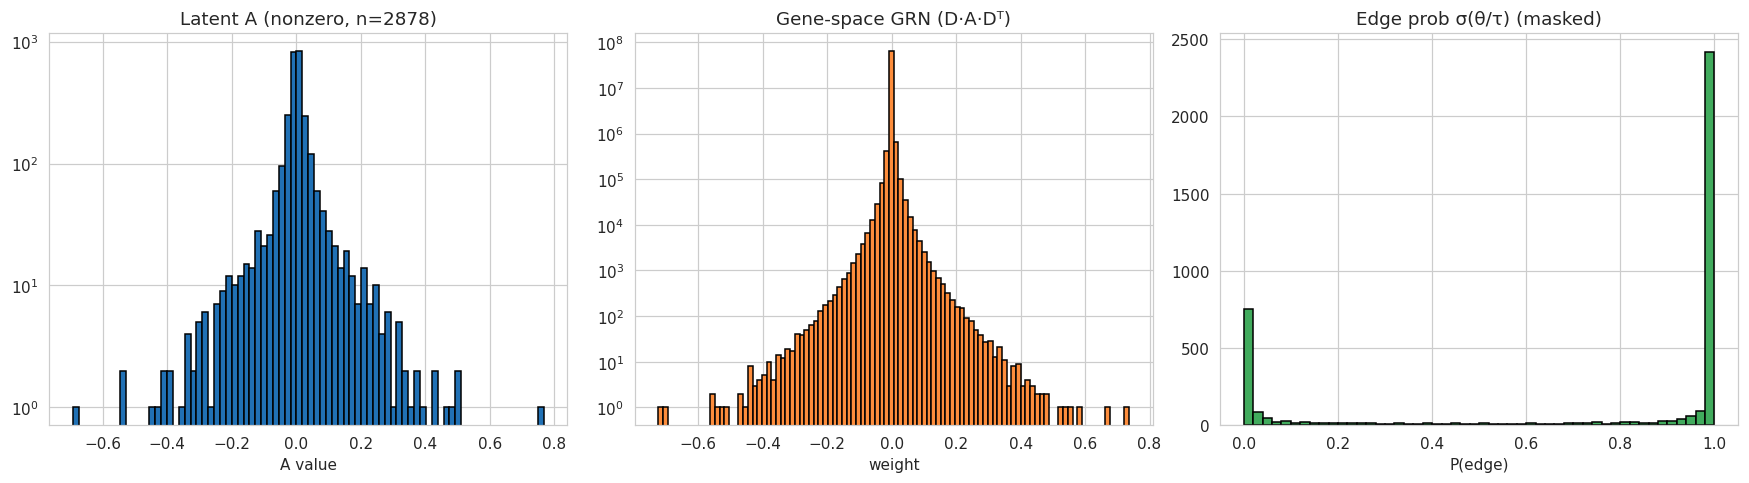

GRN |w|: mean=0.0006  std=0.0037  3σ=0.0110  99th pct=0.0121


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
a = A_eff[np.abs(A_eff) > 1e-8]
axes[0].hist(a, bins=80, color='#2171b5', edgecolor='k', log=True)
axes[0].set_title(f'Latent A (nonzero, n={a.size})'); axes[0].set_xlabel('A value')
g = GRN[np.abs(GRN) > 1e-8]
axes[1].hist(g, bins=100, color='#fd8d3c', edgecolor='k', log=True)
axes[1].set_title('Gene-space GRN (D·A·Dᵀ)'); axes[1].set_xlabel('weight')
ep = A_probs[A_probs > 1e-6]
axes[2].hist(ep, bins=50, color='#41ab5d', edgecolor='k')
axes[2].set_title('Edge prob σ(θ/τ) (masked)'); axes[2].set_xlabel('P(edge)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/edge_distributions.png', dpi=170, bbox_inches='tight'); plt.show()
w = np.abs(GRN[GRN != 0]); sig = w.std()
print(f"GRN |w|: mean={w.mean():.4f}  std={sig:.4f}  3σ={3*sig:.4f}  99th pct={np.percentile(w,99):.4f}")

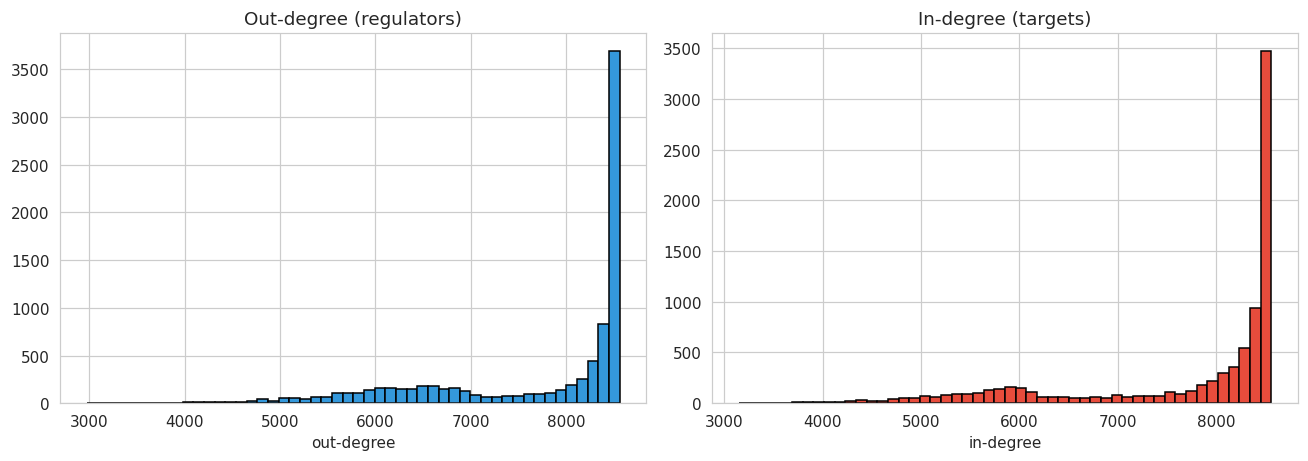

Top regulators (by out-strength):


,gene,out_strength,in_strength,out_deg,in_deg
3760,MYC,98.708168,77.986351,8562,8560
3366,CUX1,93.993362,83.340561,8561,8558
4485,HBG2,93.946922,82.314018,8557,8558
6833,HOXB2,93.588364,81.846588,8559,8559
6114,HBZ,87.380997,80.386551,8560,8557
6413,E2F4,85.974518,84.350838,8555,8551
5810,YY1,85.267120,72.442238,8559,8553
1338,STAT1,81.728310,63.669033,8559,8554
4882,KMT2A,80.994568,65.652443,8557,8551
4492,MRPL17,80.967720,67.971436,8559,8552


Top 15 edges:


,source,target,weight
0,HBG2,NFE2L2,0.736315
1,HOXB2,CUX1,-0.723197
2,NFE2L2,HBG2,-0.698081
3,CUX1,HOXB2,0.670292
4,HOXB2,E2F3,0.585371
5,HMBOX1,HBG2,-0.562518
6,CUX1,SMAD3,0.553477
7,E2F3,HOXB2,-0.553199
8,POU2F1,HBG2,-0.536363
9,HBG2,HMBOX1,0.533412


In [19]:
GRN_abs = np.abs(GRN)
gene_stats = pd.DataFrame({'gene': gene_names,
    'out_strength': GRN_abs.sum(1), 'in_strength': GRN_abs.sum(0),
    'out_deg': (GRN_abs > 1e-8).sum(1), 'in_deg': (GRN_abs > 1e-8).sum(0)}
    ).sort_values('out_strength', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].hist(gene_stats['out_deg'][gene_stats['out_deg']>0], bins=50, color='#3498db', edgecolor='k')
axes[0].set_title('Out-degree (regulators)'); axes[0].set_xlabel('out-degree')
axes[1].hist(gene_stats['in_deg'][gene_stats['in_deg']>0], bins=50, color='#e74c3c', edgecolor='k')
axes[1].set_title('In-degree (targets)'); axes[1].set_xlabel('in-degree')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/degree_distributions.png', dpi=170, bbox_inches='tight'); plt.show()
gene_stats.to_csv(f'{OUT_DIR}/gene_grn_stats.csv', index=False)
flat = GRN_abs.flatten(); top = np.argsort(flat)[::-1][:30]
top_edges = pd.DataFrame([(gene_names[i//n_genes], gene_names[i%n_genes], float(GRN.flatten()[i])) for i in top],
                         columns=['source', 'target', 'weight'])
top_edges.to_csv(f'{OUT_DIR}/top_edges.csv', index=False)
print('Top regulators (by out-strength):'); display(gene_stats.head(12))
print('Top 15 edges:'); display(top_edges.head(15))

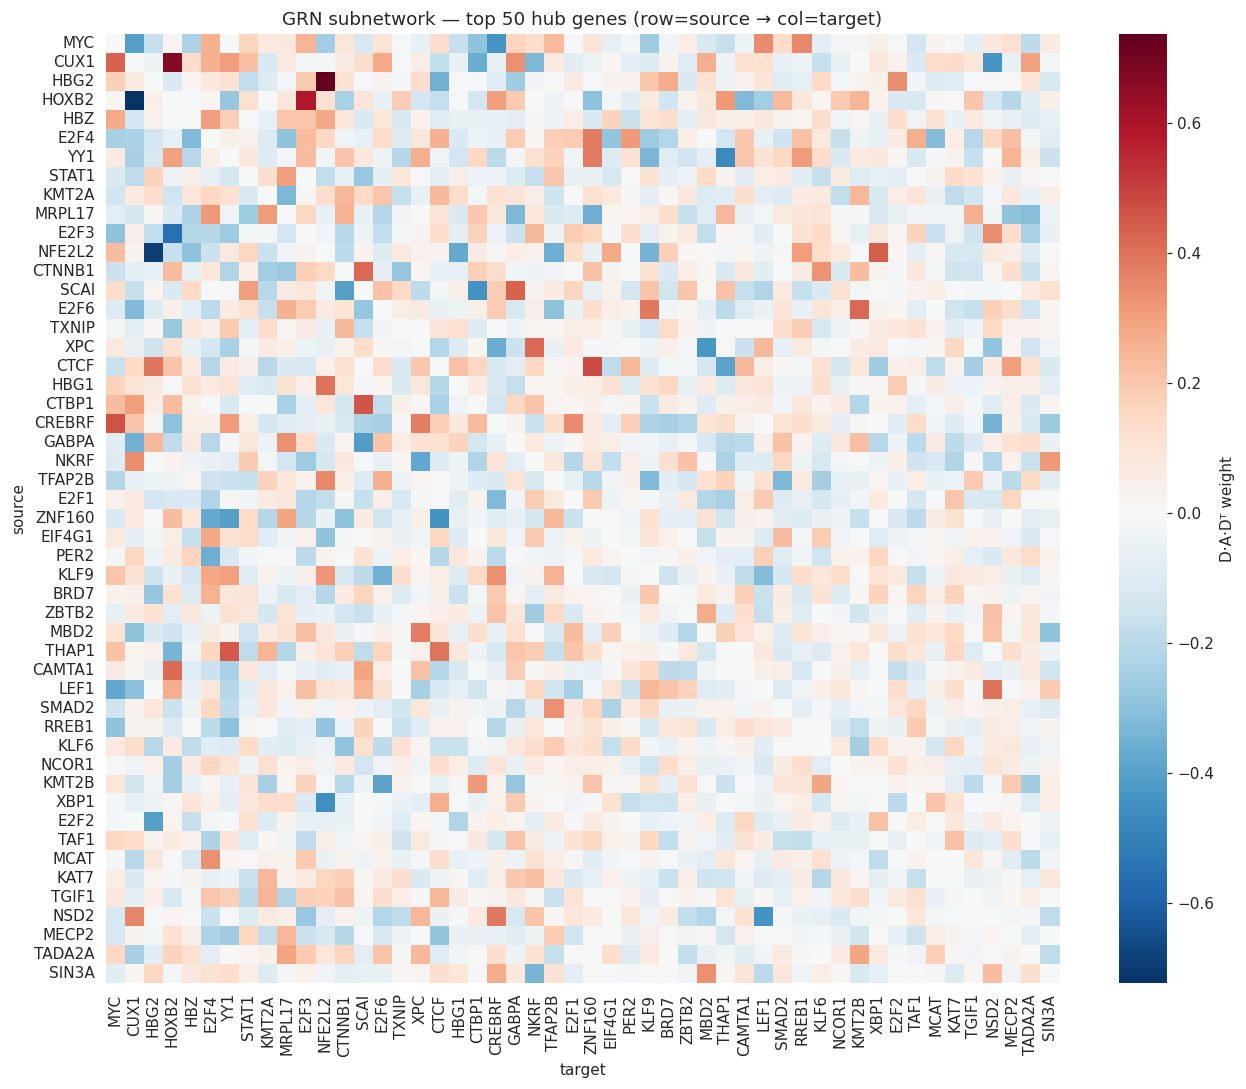

In [20]:
top50 = gene_stats.head(50)['gene'].tolist()
ix = [gene_names.index(g) for g in top50]
plt.figure(figsize=(12, 10))
sns.heatmap(GRN[np.ix_(ix, ix)], cmap='RdBu_r', center=0, xticklabels=top50, yticklabels=top50,
            cbar_kws={'label': 'D·A·Dᵀ weight'})
plt.title('GRN subnetwork — top 50 hub genes (row=source → col=target)')
plt.xlabel('target'); plt.ylabel('source'); plt.tight_layout()
plt.savefig(f'{OUT_DIR}/grn_hub_heatmap.png', dpi=170, bbox_inches='tight'); plt.show()

## 2. CollecTRI recovery (does the GRN recover known TF→target edges?)

CollecTRI: loaded 42990 TF→target pairs for organism='human'
CollecTRI: 9411 TF→target pairs in gene set; 479 unique TFs; 9207 positive edges / 73316406 (0.013%)
GRN |.|   AUROC=0.9724  AUPRC=0.0060  (prevalence 0.0001)
GRN signed AUROC=0.5353


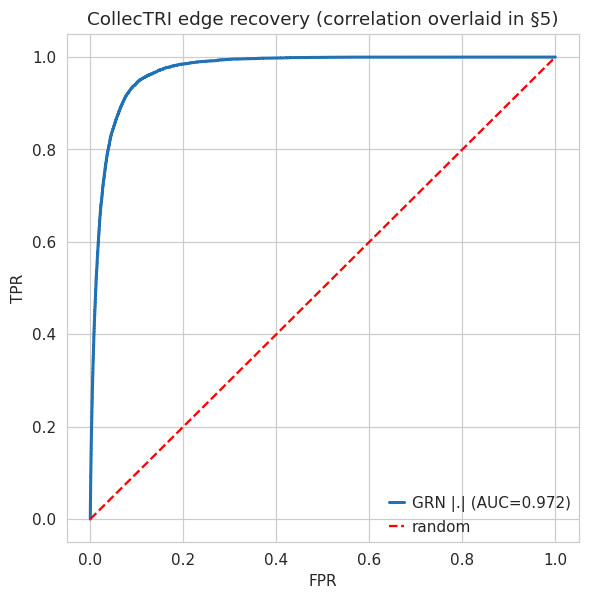

In [21]:
from utils.bio_priors import load_collectri
collectri = load_collectri()
gup = [g.upper() for g in gene_names]; gidx = {g: i for i, g in enumerate(gup)}
pairs = collectri[collectri['source'].isin(gidx) & collectri['target'].isin(gidx)].drop_duplicates(['source','target'])
prior = np.zeros((n_genes, n_genes), dtype=bool)
for s, t in zip(pairs['source'], pairs['target']):
    if s != t: prior[gidx[s], gidx[t]] = True
offdiag = ~np.eye(n_genes, dtype=bool)
y = prior[offdiag].astype(int)
print(f"CollecTRI: {len(pairs)} TF→target pairs in gene set; {pairs['source'].nunique()} unique TFs; "
      f"{y.sum()} positive edges / {y.size} ({100*y.mean():.3f}%)")
au_abs = roc_auc_score(y, np.abs(GRN)[offdiag]); ap_abs = average_precision_score(y, np.abs(GRN)[offdiag])
au_sgn = roc_auc_score(y, GRN[offdiag])
print(f"GRN |.|   AUROC={au_abs:.4f}  AUPRC={ap_abs:.4f}  (prevalence {y.mean():.4f})")
print(f"GRN signed AUROC={au_sgn:.4f}")
scorecard.update(collectri_pairs=int(len(pairs)), grn_collectri_auroc=float(au_abs),
                 grn_collectri_auprc=float(ap_abs))
fpr, tpr, _ = roc_curve(y, np.abs(GRN)[offdiag])
plt.figure(figsize=(6, 6)); plt.plot(fpr, tpr, color='#2171b5', lw=2, label=f'GRN |.| (AUC={au_abs:.3f})')
plt.plot([0,1],[0,1],'r--', label='random')
plt.xlabel('FPR'); plt.ylabel('TPR'); plt.legend(); plt.title('CollecTRI edge recovery (correlation overlaid in §5)')
plt.savefig(f'{OUT_DIR}/collectri_roc_grn.png', dpi=170, bbox_inches='tight'); plt.show()

### 2b. Did the margin-ranking prior loss shift prior-edge weights up?

`biological_prior_loss` is a margin-ranking that pushes CollecTRI edges **above**
random background edges on `G_feat = D·A·Dᵀ`. If it worked, the weight
distribution of in-prior edges (red) should sit to the **right** of the
not-in-prior background (white). NOTE the loss optimizes `G_feat` built from edge
**probabilities** (`get_edge_probs`), so we show both that matrix (right panel —
faithful to the loss) and the signed inference GRN (left panel).

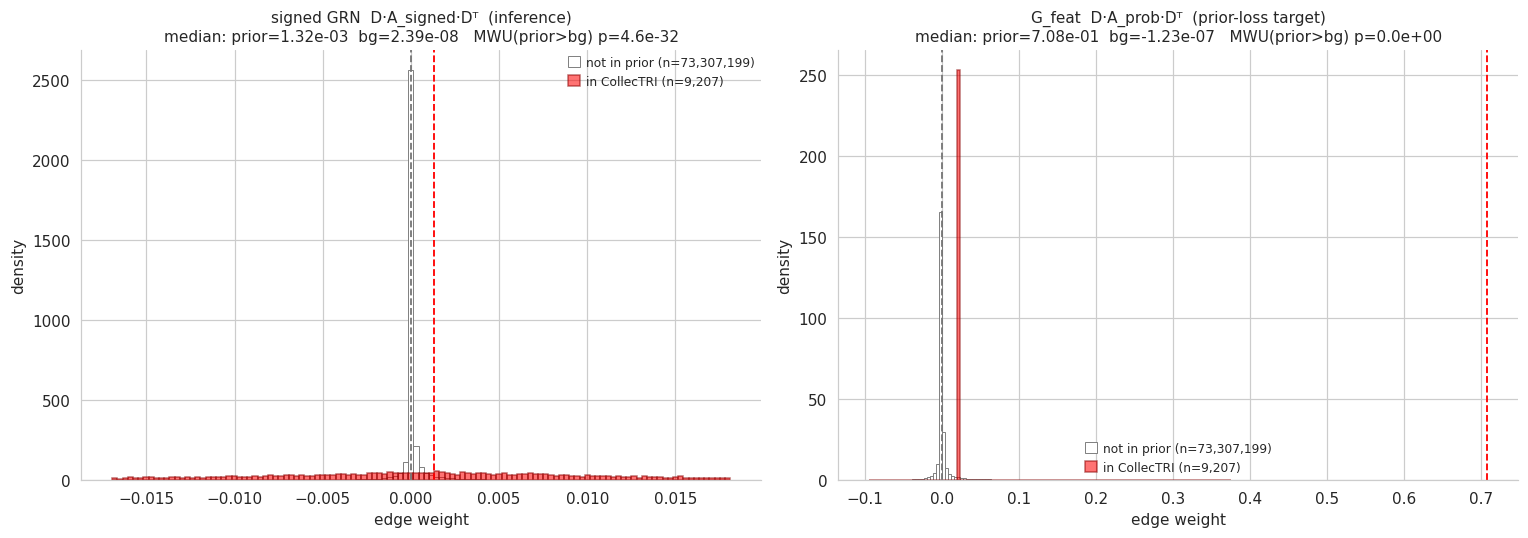

prior-loss G_feat: in-prior median=7.083e-01  background median=-1.229e-07  MWU(prior>bg) p=0.00e+00


In [22]:
from scipy.stats import mannwhitneyu as _mwu
G_prob = D @ A_probs @ D.T                      # what the prior margin-loss optimizes
np.fill_diagonal(G_prob, 0.0)
prior_off = prior[offdiag]                      # bool aligned with vals = mat[offdiag]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (mat, title) in zip(axes, [(GRN, 'signed GRN  D·A_signed·Dᵀ  (inference)'),
                                   (G_prob, 'G_feat  D·A_prob·Dᵀ  (prior-loss target)')]):
    vals = mat[offdiag]
    bg = vals[~prior_off]; sig = vals[prior_off]
    U, p = _mwu(sig, bg, alternative='greater')   # H1: prior edges > background
    lo, hi = np.percentile(vals, [0.3, 99.7]); bins = np.linspace(lo, hi, 120)
    ax.hist(bg, bins=bins, density=True, color='white', edgecolor='#777', lw=0.6,
            label=f'not in prior (n={bg.size:,})')
    ax.hist(sig, bins=bins, density=True, color='red', alpha=0.55, edgecolor='darkred',
            label=f'in CollecTRI (n={sig.size:,})')
    ax.axvline(np.median(bg), color='#777', ls='--', lw=1.2)
    ax.axvline(np.median(sig), color='red', ls='--', lw=1.2)
    ax.set_xlabel('edge weight'); ax.set_ylabel('density'); ax.legend(fontsize=8)
    ax.set_title(f'{title}\nmedian: prior={np.median(sig):.2e}  bg={np.median(bg):.2e}   '
                 f'MWU(prior>bg) p={p:.1e}', fontsize=10)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/prior_edge_weight_shift.png', dpi=170, bbox_inches='tight'); plt.show()
# record the loss-faithful (probability G_feat) shift
_vp = G_prob[offdiag]; _U, _p = _mwu(_vp[prior_off], _vp[~prior_off], alternative='greater')
scorecard.update(prior_shift_mwu_p=float(_p),
                 prior_edge_median=float(np.median(_vp[prior_off])),
                 bg_edge_median=float(np.median(_vp[~prior_off])))
print(f"prior-loss G_feat: in-prior median={np.median(_vp[prior_off]):.3e}  "
      f"background median={np.median(_vp[~prior_off]):.3e}  MWU(prior>bg) p={_p:.2e}")

## 3. Causal directionality — TF→target vs target→TF asymmetry

A *correlation* network is symmetric: `G[i,j] == G[j,i]`. A *causal* network should
score known **TF→target** edges higher than their reverse. We test this with a
Mann-Whitney U (one-sided, forward > reverse) and a global asymmetry score.

TF→target |w| median=0.0106   target→TF |w| median=0.0098
Mann-Whitney U (forward > reverse): U=44002580  p=3.620e-06
Global GRN asymmetry  ‖G−Gᵀ‖/‖G+Gᵀ‖ = 3.518   (0 = symmetric/correlation-like, →1 = fully directed)


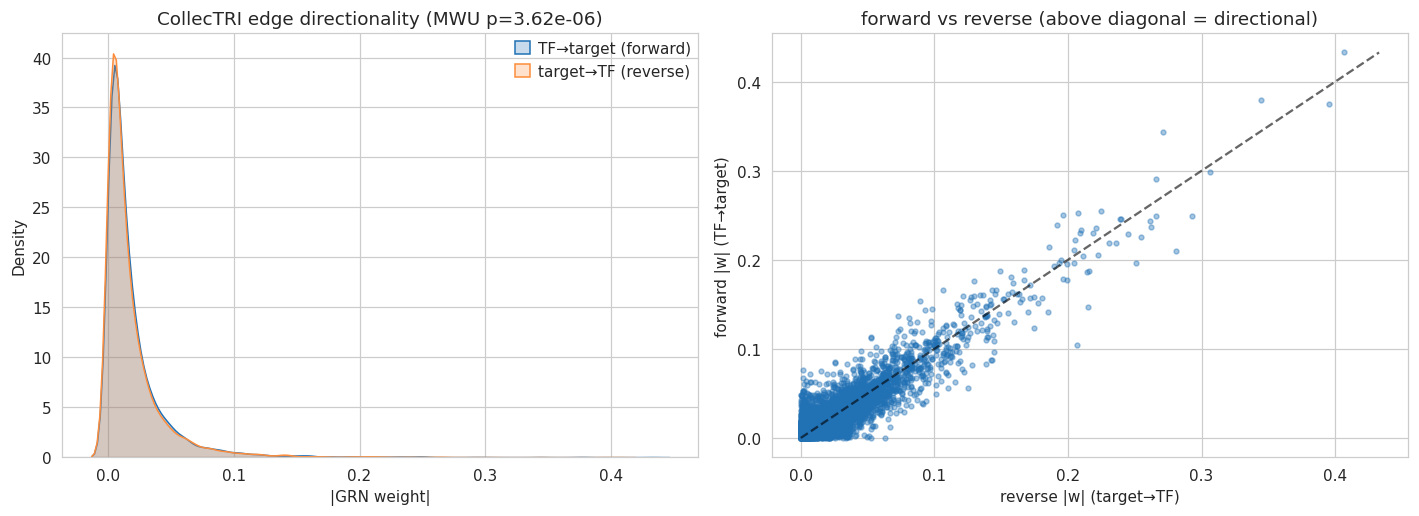

In [23]:
fwd, rev = [], []
for s, t in zip(pairs['source'], pairs['target']):
    if s == t: continue
    fwd.append(abs(GRN[gidx[s], gidx[t]])); rev.append(abs(GRN[gidx[t], gidx[s]]))
fwd, rev = np.array(fwd), np.array(rev)
if len(fwd) > 5:
    U, p = mannwhitneyu(fwd, rev, alternative='greater')
    print(f"TF→target |w| median={np.median(fwd):.4f}   target→TF |w| median={np.median(rev):.4f}")
    print(f"Mann-Whitney U (forward > reverse): U={U:.0f}  p={p:.3e}")
else:
    p = np.nan; print("too few CollecTRI pairs for MWU")
asym = float(np.linalg.norm(GRN - GRN.T) / (np.linalg.norm(GRN + GRN.T) + 1e-12))
print(f"Global GRN asymmetry  ‖G−Gᵀ‖/‖G+Gᵀ‖ = {asym:.3f}   (0 = symmetric/correlation-like, →1 = fully directed)")
scorecard.update(asym_fwd_median=float(np.median(fwd)) if len(fwd) else None,
                 asym_rev_median=float(np.median(rev)) if len(rev) else None,
                 asym_mwu_p=float(p), global_asymmetry=asym)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.kdeplot(fwd, ax=axes[0], fill=True, color='#2171b5', label='TF→target (forward)')
sns.kdeplot(rev, ax=axes[0], fill=True, color='#fd8d3c', label='target→TF (reverse)')
axes[0].set_xlabel('|GRN weight|'); axes[0].legend()
axes[0].set_title(f'CollecTRI edge directionality (MWU p={p:.2e})')
m = max(fwd.max(), rev.max()) if len(fwd) else 1
axes[1].scatter(rev, fwd, s=10, alpha=0.4, color='#2171b5'); axes[1].plot([0, m], [0, m], 'k--', alpha=0.6)
axes[1].set_xlabel('reverse |w| (target→TF)'); axes[1].set_ylabel('forward |w| (TF→target)')
axes[1].set_title('forward vs reverse (above diagonal = directional)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/directionality_asymmetry.png', dpi=170, bbox_inches='tight'); plt.show()

## 4. Decoder / latent disentanglement

programs/gene (>10% of peak loading): mean=2.5  median=2
genes/program (>10% of peak): mean=328.4
DᵀD mean|off-diag|/mean|diag| = 0.0002  (0 = perfectly orthogonal programs)


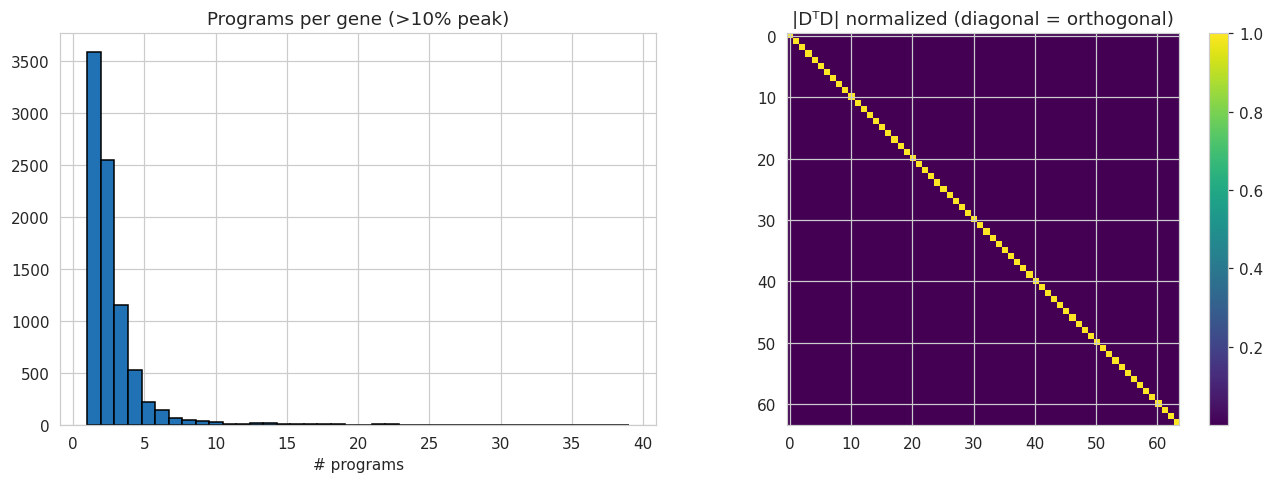

In [24]:
D_sq = D**2
L = D_sq / (D_sq.max(1, keepdims=True) + 1e-12)         # row-max-normalized loadings
prog_per_gene = (L > 0.1).sum(1); genes_per_prog = (L > 0.1).sum(0)
DtD = D.T @ D
offm = np.abs(DtD - np.diag(np.diag(DtD))); ortho_ratio = float(offm.mean() / (np.abs(np.diag(DtD)).mean() + 1e-12))
print(f"programs/gene (>10% of peak loading): mean={prog_per_gene.mean():.1f}  median={np.median(prog_per_gene):.0f}")
print(f"genes/program (>10% of peak): mean={genes_per_prog.mean():.1f}")
print(f"DᵀD mean|off-diag|/mean|diag| = {ortho_ratio:.4f}  (0 = perfectly orthogonal programs)")
scorecard.update(programs_per_gene=float(prog_per_gene.mean()), ortho_offdiag_ratio=ortho_ratio)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hist(prog_per_gene, bins=40, color='#2171b5', edgecolor='k')
axes[0].set_title('Programs per gene (>10% peak)'); axes[0].set_xlabel('# programs')
im = axes[1].imshow(np.abs(DtD) / (np.abs(DtD).max() + 1e-12), cmap='viridis')
plt.colorbar(im, ax=axes[1]); axes[1].set_title('|DᵀD| normalized (diagonal = orthogonal)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/disentanglement_decoder.png', dpi=170, bbox_inches='tight'); plt.show()

## 5. Load cells → correlation baseline + latent disentanglement

In [25]:
import yaml, scipy.sparse
cfgs = sorted(glob.glob(os.path.join(EXP_DIR, 'configs', 'exp*.yaml')))
config = yaml.safe_load(open(cfgs[0])) if cfgs else ckpt['config']
from data.load_replogle import load_replogle
dd = load_replogle(path=config['data']['replogle_path'], n_hvg=config['data']['n_hvg'],
                   cell_line=config['data'].get('replogle_cell_line', 'k562'),
                   max_cells=min(MAX_CELLS, config['data'].get('replogle_max_cells', MAX_CELLS)),
                   train_frac=config['data'].get('single_pert_train_frac', 0.8),
                   val_frac=config['data'].get('single_pert_val_frac', 0.1),
                   split_seed=config['data'].get('split_seed', 42))
ad = dd['adata']
Xall = ad.X.toarray() if scipy.sparse.issparse(ad.X) else np.asarray(ad.X); Xall = Xall.astype('float32')
assert list(dd['gene_names']) == gene_names, "data gene axis != checkpoint — config/n_hvg/seed mismatch"
ctrl_idx = np.array(dd['control_idx'])
rng = np.random.default_rng(0)
pert_idx = np.array(sorted(set(range(ad.n_obs)) - set(ctrl_idx.tolist())))
n_each = int(min(5000, len(ctrl_idx), len(pert_idx)))
sel_c = rng.choice(ctrl_idx, n_each, replace=False); sel_p = rng.choice(pert_idx, n_each, replace=False)
sel = np.concatenate([sel_c, sel_p]); labels = np.array([0]*n_each + [1]*n_each)
with torch.no_grad():
    Xsel = torch.tensor(Xall[sel], dtype=torch.float32, device=DEVICE)
    _, _, eps = model.encoder(Xsel)
    z = model.dag.scm_forward(eps, model.dag.sample_A(1).squeeze(0))
eps_np, z_np = eps.cpu().numpy(), z.cpu().numpy()
print(f"encoded {len(sel)} cells ({n_each} control + {n_each} perturbed)")

Loading Replogle dataset from /large_storage/ctc/userspace/aadduri/revisions/replogle_unfiltered/K562_essential_raw_singlecell_01.h5ad...
  File size: 10.66 GB
  Full shape: (310385, 8563)
  Renamed var_names from ENSG → gene symbol (8561 unique symbols, 2 suffixed for duplicates)
  No `cell_line` column — assuming file is already k562-only (skipping cell-line filter).
  After downsampling to 40000: 40000 cells
  X dtype: float32, sparse: False
  Preprocessing...
  After preprocessing: (40000, 8563)
  Control cells: 1370
  Single perturbations: 2048 genes
  Computing differential expression...
  Pert split: 1638 train, 205 val, 205 test genes
  gem_groups: 48 unique (batch-effect conditioning enabled)
encoded 2740 cells (1370 control + 1370 perturbed)


CollecTRI AUROC — GRN |.|=0.9724   correlation=0.5353


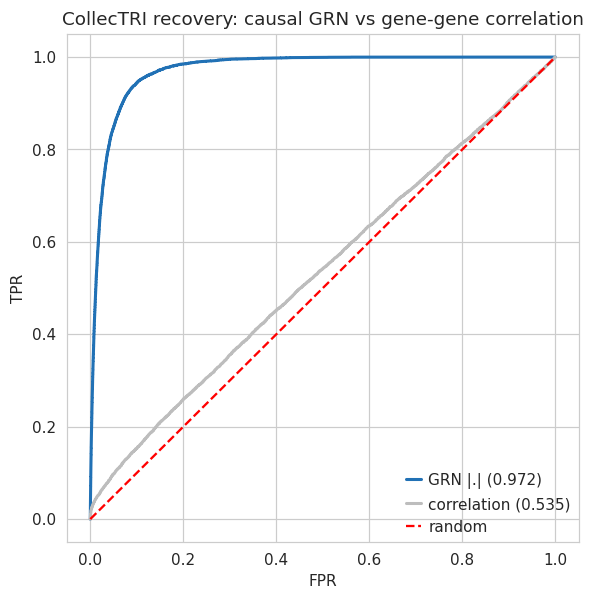

latent z mean|off-diag correlation| = 0.4557


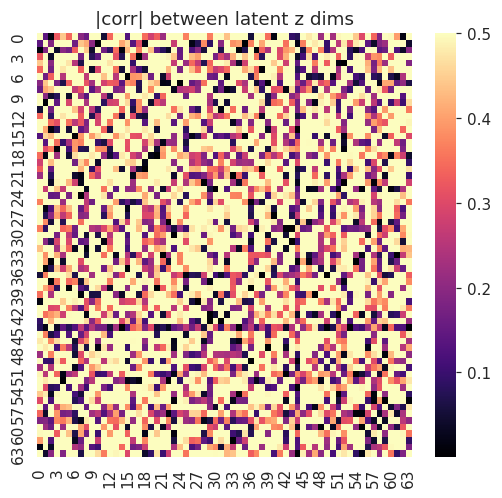

In [26]:
# Correlation baseline on CollecTRI (control cells) + GRN-vs-corr ROC
Xc = Xall[ctrl_idx]
corr = np.nan_to_num(np.abs(np.corrcoef(Xc.T))); np.fill_diagonal(corr, 0)
au_corr = roc_auc_score(y, corr[offdiag])
print(f"CollecTRI AUROC — GRN |.|={scorecard['grn_collectri_auroc']:.4f}   correlation={au_corr:.4f}")
scorecard.update(corr_collectri_auroc=float(au_corr))
plt.figure(figsize=(6, 6))
for mat, lab, col in [(np.abs(GRN), f"GRN |.| ({scorecard['grn_collectri_auroc']:.3f})", '#2171b5'),
                      (corr, f'correlation ({au_corr:.3f})', '#bdbdbd')]:
    fpr, tpr, _ = roc_curve(y, mat[offdiag]); plt.plot(fpr, tpr, lw=2, color=col, label=lab)
plt.plot([0,1],[0,1],'r--', label='random'); plt.legend(); plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('CollecTRI recovery: causal GRN vs gene-gene correlation')
plt.savefig(f'{OUT_DIR}/collectri_roc_grn_vs_corr.png', dpi=170, bbox_inches='tight'); plt.show()
# latent z off-diagonal correlation (disentanglement)
zc = np.corrcoef(z_np.T); off = np.abs(zc[~np.eye(d, dtype=bool)])
print(f"latent z mean|off-diag correlation| = {off.mean():.4f}")
scorecard.update(latent_offdiag_corr=float(off.mean()))
plt.figure(figsize=(5.5, 5)); sns.heatmap(np.abs(zc), cmap='magma', vmax=0.5)
plt.title('|corr| between latent z dims'); plt.savefig(f'{OUT_DIR}/latent_corr.png', dpi=170, bbox_inches='tight'); plt.show()

### 5b. Held-out CollecTRI recovery — copying the prior, or generalizing? (exp9)

If the model was trained with a prior-edge holdout (`phase1.prior_train_frac < 1`,
e.g. holding out whole TFs), this asks the un-tautological question: does `G`
score the **held-out** CollecTRI edges (never supervised) above background, and
above the correlation floor? Copying ⇒ held-out AUROC ≈ chance while train-edge
AUROC is high. Generalizing ⇒ held-out AUROC clearly beats the corr floor.
No-op for full-supervision checkpoints.

In [27]:
ptf = (ckpt.get('config', {}) or {}).get('phase1', {})
prior_train_frac = float(ptf.get('prior_train_frac', 1.0))
if prior_train_frac < 1.0:
    from utils.bio_priors import split_collectri_edges
    name_pairs = list(zip(pairs['source'], pairs['target']))      # uppercase, in gene set
    train_set, test_set = split_collectri_edges(
        name_pairs, prior_train_frac=prior_train_frac,
        prior_split_seed=int(ptf.get('prior_split_seed', 0)),
        prior_split_mode=ptf.get('prior_split_mode', 'tf'))
    prior_train = np.zeros((n_genes, n_genes), bool); prior_test = np.zeros((n_genes, n_genes), bool)
    for s, t in train_set:
        if s != t: prior_train[gidx[s], gidx[t]] = True
    for s, t in test_set:
        if s != t: prior_test[gidx[s], gidx[t]] = True

    def split_auroc(pos_mask, other_mask, score):
        # positives = this split's edges; negatives = true non-edges (exclude the
        # OTHER split so train/test edges never pollute each other's negatives).
        keep = offdiag & ~other_mask
        yv = pos_mask[keep].astype(int); sv = np.abs(score)[keep]
        return roc_auc_score(yv, sv) if 0 < yv.sum() < yv.size else np.nan

    grn_train = split_auroc(prior_train, prior_test, GRN)
    grn_test = split_auroc(prior_test, prior_train, GRN)          # ← the held-out number
    corr_test = split_auroc(prior_test, prior_train, corr)        # ← the floor
    gprob_test = split_auroc(prior_test, prior_train, G_prob)
    print(f"Held-out CollecTRI recovery (mode={ptf.get('prior_split_mode','tf')}, "
          f"train_frac={prior_train_frac}):  {int(prior_train.sum())} train / {int(prior_test.sum())} held-out edges")
    print(f"  |GRN|  train-edge AUROC = {grn_train:.4f}   held-out AUROC = {grn_test:.4f}")
    print(f"  G_prob held-out AUROC  = {gprob_test:.4f}")
    print(f"  correlation held-out FLOOR AUROC = {corr_test:.4f}")
    verdict = ('COPYING (held-out≈chance)' if grn_test < 0.55 else
               ('GENERALIZING (held-out > corr floor)' if grn_test > corr_test + 0.03 else 'AMBIGUOUS'))
    print(f"  ⇒ {verdict}")
    scorecard.update(grn_heldout_auroc=float(grn_test), grn_trainedge_auroc=float(grn_train),
                     corr_heldout_floor_auroc=float(corr_test), gprob_heldout_auroc=float(gprob_test),
                     prior_split_mode=ptf.get('prior_split_mode', 'tf'), prior_train_frac=prior_train_frac)
    fig, ax = plt.subplots(figsize=(6, 6))
    for mask, other, lab, col in [(prior_train, prior_test, f'train edges ({grn_train:.3f})', '#2171b5'),
                                  (prior_test, prior_train, f'held-out ({grn_test:.3f})', '#41ab5d')]:
        keep = offdiag & ~other
        fpr, tpr, _ = roc_curve(mask[keep].astype(int), np.abs(GRN)[keep]); ax.plot(fpr, tpr, color=col, lw=2, label=lab)
    keep = offdiag & ~prior_train
    fpr, tpr, _ = roc_curve(prior_test[keep].astype(int), corr[keep]); ax.plot(fpr, tpr, '--', color='#bdbdbd', lw=2, label=f'corr held-out floor ({corr_test:.3f})')
    ax.plot([0, 1], [0, 1], 'r:'); ax.legend(); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
    ax.set_title('Held-out CollecTRI recovery: train vs held-out vs corr floor')
    plt.savefig(f'{OUT_DIR}/collectri_heldout_roc.png', dpi=170, bbox_inches='tight'); plt.show()
else:
    print("prior_train_frac = 1.0 (no holdout) — held-out recovery N/A. "
          "Run an exp9 cell with prior_train_frac < 1 to assess copying vs generalizing.")

prior_train_frac = 1.0 (no holdout) — held-out recovery N/A. Run an exp9 cell with prior_train_frac < 1 to assess copying vs generalizing.


## 6. Perturbed vs control separation (UMAP + linear separability)

perturbed-vs-control 5-fold logreg AUROC:  z (post-SCM)=0.974   ε (exogenous)=0.974
silhouette(z, perturbed/control) = 0.276


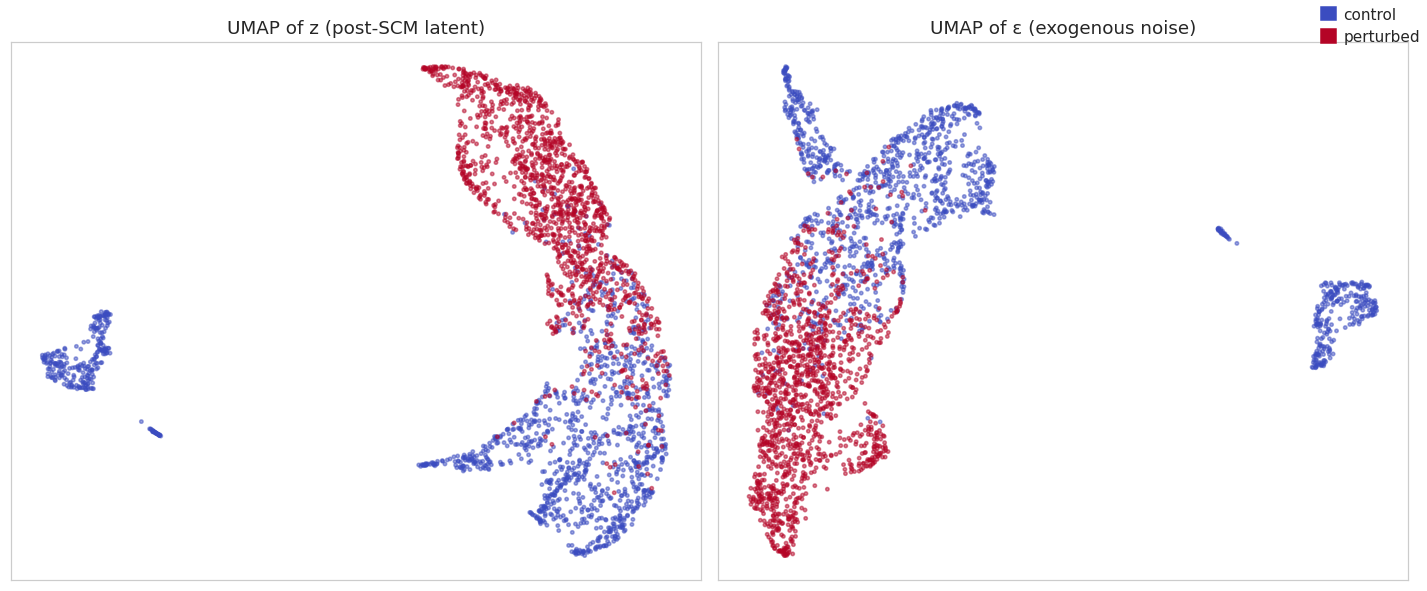

In [28]:
import umap
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.metrics import silhouette_score
auc_z = cross_val_score(LogisticRegression(max_iter=600), z_np, labels, cv=5, scoring='roc_auc').mean()
auc_e = cross_val_score(LogisticRegression(max_iter=600), eps_np, labels, cv=5, scoring='roc_auc').mean()
sil_z = float(silhouette_score(z_np, labels))
print(f"perturbed-vs-control 5-fold logreg AUROC:  z (post-SCM)={auc_z:.3f}   ε (exogenous)={auc_e:.3f}")
print(f"silhouette(z, perturbed/control) = {sil_z:.3f}")
scorecard.update(pert_vs_ctrl_auroc_z=float(auc_z), pert_vs_ctrl_auroc_eps=float(auc_e), silhouette_z=sil_z)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, mat, t in [(axes[0], z_np, 'z (post-SCM latent)'), (axes[1], eps_np, 'ε (exogenous noise)')]:
    e = umap.UMAP(random_state=42, n_neighbors=30, min_dist=0.3).fit_transform(mat)
    sca = ax.scatter(e[:,0], e[:,1], c=labels, cmap='coolwarm', s=5, alpha=0.5)
    ax.set_title(f'UMAP of {t}'); ax.set_xticks([]); ax.set_yticks([])
import matplotlib.patches as mpatches
fig.legend(handles=[mpatches.Patch(color=plt.cm.coolwarm(0.0), label='control'),
                    mpatches.Patch(color=plt.cm.coolwarm(1.0), label='perturbed')], loc='upper right')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/umap_perturbed_vs_control.png', dpi=170, bbox_inches='tight'); plt.show()

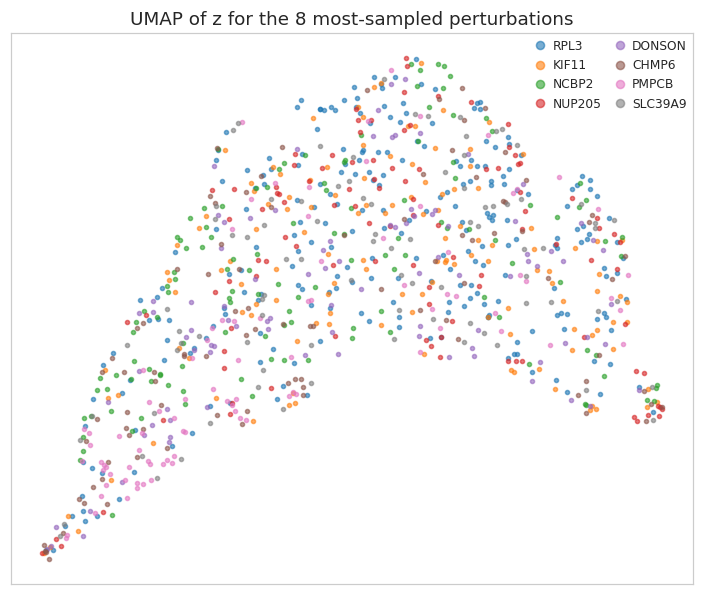

In [29]:
# Bonus: UMAP colored by the top perturbations (do same-target cells cluster?)
try:
    sp = dd['single_perts']; g2i = {g: i for i, g in enumerate(gene_names)}
    top_perts = sorted(sp.items(), key=lambda kv: -len(kv[1]))[:8]
    cells, labs = [], []
    for gene, idxs in top_perts:
        take = list(idxs)[:400]; cells += take; labs += [gene]*len(take)
    cells = np.array(cells)
    with torch.no_grad():
        _, _, e2 = model.encoder(torch.tensor(Xall[cells], dtype=torch.float32, device=DEVICE))
        z2 = model.dag.scm_forward(e2, model.dag.sample_A(1).squeeze(0)).cpu().numpy()
    emb = umap.UMAP(random_state=42, n_neighbors=30, min_dist=0.3).fit_transform(z2)
    plt.figure(figsize=(8, 6.5))
    for gene in dict.fromkeys(labs):
        m = np.array(labs) == gene
        plt.scatter(emb[m, 0], emb[m, 1], s=7, alpha=0.6, label=gene)
    plt.legend(markerscale=2, fontsize=8, ncol=2); plt.xticks([]); plt.yticks([])
    plt.title('UMAP of z for the 8 most-sampled perturbations')
    plt.savefig(f'{OUT_DIR}/umap_by_perturbation.png', dpi=170, bbox_inches='tight'); plt.show()
except Exception as ex:
    print('per-perturbation UMAP skipped:', ex)

## 7. Scorecard — is the DAG/model good enough for RL?

In [30]:
def line(name, val, target, cmp='>', fmt='{:.3f}'):
    try:
        ok = (val > target) if cmp == '>' else (val < target)
    except Exception:
        ok = False
    vs = fmt.format(val) if isinstance(val, (int, float)) and val == val else str(val)
    print(f"  {name:46s} {vs:>10s}   {'PASS' if ok else '·   '}  (target {cmp} {target})")

print('='*74); print('  DAG / MODEL QUALITY SCORECARD'); print('='*74)
line('CollecTRI recovery AUROC (causal GRN)', scorecard.get('grn_collectri_auroc'), 0.55)
line('  GRN beats correlation baseline', scorecard.get('grn_collectri_auroc', 0), scorecard.get('corr_collectri_auroc', 1))
line('Causal asymmetry MWU p (forward>reverse)', scorecard.get('asym_mwu_p'), 0.05, '<', '{:.2e}')
line('Global GRN asymmetry (directed-ness)', scorecard.get('global_asymmetry'), 0.10)
line('Perturbed-vs-control AUROC (latent z)', scorecard.get('pert_vs_ctrl_auroc_z'), 0.80)
line('DAGMA acyclicity h(A) → 0', scorecard.get('dagma_h'), 1e-2, '<', '{:.2e}')
line('Latent off-diag |corr| (disentangle)', scorecard.get('latent_offdiag_corr'), 0.15, '<')
print('='*74)
json.dump(scorecard, open(f'{OUT_DIR}/scorecard.json', 'w'), indent=2)
print('saved', f'{OUT_DIR}/scorecard.json')
display(pd.Series(scorecard).to_frame('value'))

  DAG / MODEL QUALITY SCORECARD
  CollecTRI recovery AUROC (causal GRN)               0.972   PASS  (target > 0.55)
    GRN beats correlation baseline                    0.972   PASS  (target > 0.5353254905171727)
  Causal asymmetry MWU p (forward>reverse)         3.62e-06   PASS  (target < 0.05)
  Global GRN asymmetry (directed-ness)                3.518   PASS  (target > 0.1)
  Perturbed-vs-control AUROC (latent z)               0.974   PASS  (target > 0.8)
  DAGMA acyclicity h(A) → 0                        9.02e-01   ·     (target < 0.01)
  Latent off-diag |corr| (disentangle)                0.456   ·     (target < 0.15)
saved /home/sgoudarzi/scCausalRL/experiments/exp8_dag_revival_grid/results/phase1/dag_analysis/scorecard.json


,value
latent_dim,6.400000e+01
n_genes,8.563000e+03
spectral_radius,8.485734e-01
dagma_h,9.017868e-01
edge_density,7.026367e-01
collectri_pairs,9.411000e+03
grn_collectri_auroc,9.724144e-01
grn_collectri_auprc,6.022464e-03
prior_shift_mwu_p,0.000000e+00
prior_edge_median,7.083386e-01
